In [1]:
results = """
========================================================================================================================
PURE PURSUIT EXPERIMENT RESULTS
========================================================================================================================
Track                   mu   Seed   Steps Collision   Laps  Time(s)  Wall(s) Status       Lap times (s)
------------------------------------------------------------------------------------------------------------------------
YasMarina_10489     1.0000     42   22428 No             2   448.56      7.8 OK           [224.3s  224.2s]
YasMarina_10489     0.9000     42   22431 No             2   448.62      7.7 OK           [224.3s  224.3s]
YasMarina_10489     0.8000     42   22435 No             2   448.70      7.7 OK           [224.4s  224.3s]
YasMarina_10489     0.7000     42   22439 No             2   448.78      7.5 OK           [224.4s  224.3s]
YasMarina_10489     0.6000     42   22448 No             2   448.96      7.7 OK           [224.5s  224.4s]
YasMarina_10489     0.5000     42   22458 No             2   449.16      7.8 OK           [224.6s  224.5s]
YasMarina_10489     0.4000     42   22475 No             2   449.50      7.2 OK           [224.8s  224.7s]
YasMarina_10489     0.3000     42   22506 No             2   450.12      7.7 OK           [225.1s  225.0s]
YasMarina_10489     0.2000     42   22567 No             2   451.34      7.3 OK           [225.7s  225.6s]
YasMarina_10489     0.1000     42   22770 No             2   455.40      7.7 OK           [227.8s  227.6s]
Sepang_10489        1.0000     42   27654 No             2   553.08     10.1 OK           [276.6s  276.5s]
Sepang_10489        0.9000     42   27657 No             2   553.14      9.9 OK           [276.6s  276.5s]
Sepang_10489        0.8000     42   27660 No             2   553.20     10.4 OK           [276.6s  276.6s]
Sepang_10489        0.7000     42   27662 No             2   553.24     10.2 OK           [276.6s  276.6s]
Sepang_10489        0.6000     42   27667 No             2   553.34     10.1 OK           [276.7s  276.7s]
Sepang_10489        0.5000     42   27673 No             2   553.46     10.0 OK           [276.8s  276.7s]
Sepang_10489        0.4000     42   27684 No             2   553.68     10.0 OK           [276.9s  276.8s]
Sepang_10489        0.3000     42   27702 No             2   554.04     10.3 OK           [277.0s  277.0s]
Sepang_10489        0.2000     42   27736 No             2   554.72      9.9 OK           [277.4s  277.3s]
Sepang_10489        0.1000     42   27838 No             2   556.76     10.0 OK           [278.4s  278.4s]
========================================================================================================================
"""

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

def parse_results(text):
    rows = []
    for line in text.strip().split("\n"):
        parts = line.split()
        if len(parts) < 6:
            continue
        if "Sepang" not in parts[0] and "YasMarina" not in parts[0]:
            continue
        track = parts[0].split("_")[0]
        collision = 1 if parts[4] == "YES" else 0
        lap_times = []
        match = re.search(r'\[([^\]]+)\]', line)
        if match and match.group(1).strip():
            lap_times = [float(t.replace('s', '')) for t in match.group(1).split()]
        rows.append({
            "track": track,
            "mu": float(parts[1]),
            "seed": int(parts[2]),
            "collision": collision,
            "lap_times": lap_times,
            "fastest_lap": min(lap_times) if lap_times else np.nan,
            "avg_lap": np.mean(lap_times) if lap_times else np.nan,
        })
    return rows

df = pd.DataFrame(parse_results(results))
print(f"Parsed {len(df)} rows ({df['collision'].sum()} collisions)")
print(f"Tracks: {sorted(df['track'].unique())}")
print(f"Mus: {sorted(df['mu'].unique())}")
print(f"Seeds: {sorted(df['seed'].unique())}")


Parsed 20 rows (0 collisions)
Tracks: ['Sepang', 'YasMarina']
Mus: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
Seeds: [42]


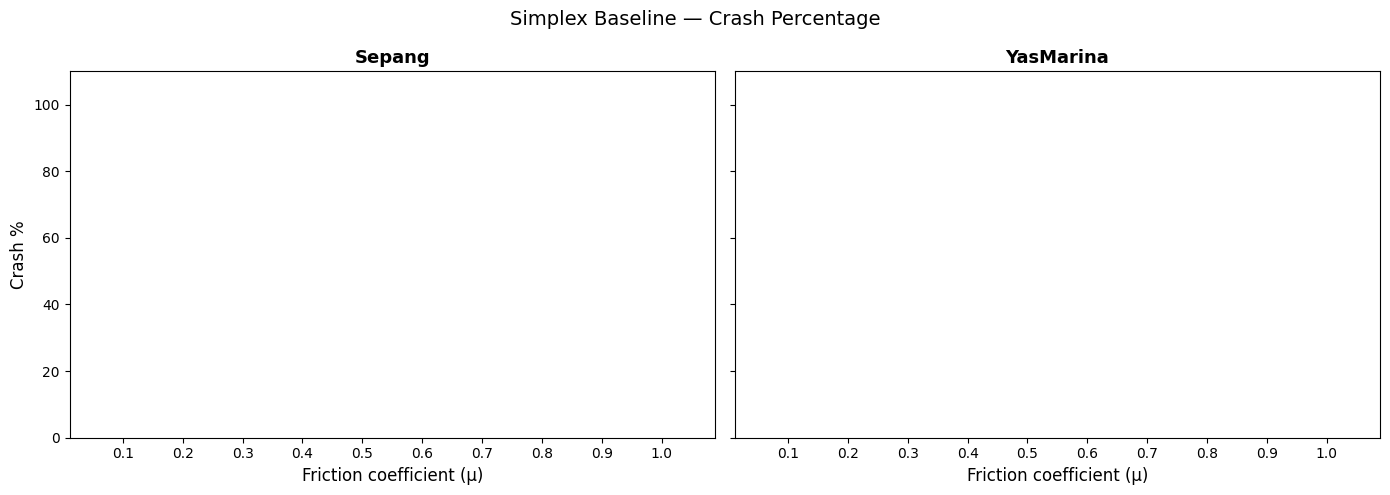

In [3]:
# --- Crash percentage bar chart: one subplot per track ---
crash_pct = df.groupby(["track", "mu"])["collision"].mean() * 100
crash_pct = crash_pct.reset_index().rename(columns={"collision": "crash_pct"})

tracks = sorted(df["track"].unique())
mus = sorted(df["mu"].unique())

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, track in zip(axes, tracks):
    sub = crash_pct[crash_pct["track"] == track].set_index("mu").reindex(mus).fillna(0)
    colors = plt.cm.RdYlGn_r(sub["crash_pct"].values / 100)
    bars = ax.bar([f"{m:.1f}" for m in mus], sub["crash_pct"].values, color=colors, edgecolor="gray", linewidth=0.5)

    for bar, val in zip(bars, sub["crash_pct"].values):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                    f"{val:.0f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")

    ax.set_xlabel("Friction coefficient (μ)", fontsize=12)
    ax.set_title(f"{track}", fontsize=13, fontweight="bold")
    ax.set_ylim(0, 110)

axes[0].set_ylabel("Crash %", fontsize=12)
fig.suptitle("Simplex Baseline — Crash Percentage", fontsize=14)
plt.tight_layout()
# plt.savefig("crash_pct_simplex_baseline.png", dpi=150, bbox_inches="tight")
# plt.savefig("crash_pct_simplex_baseline.pdf", bbox_inches="tight")
plt.show()


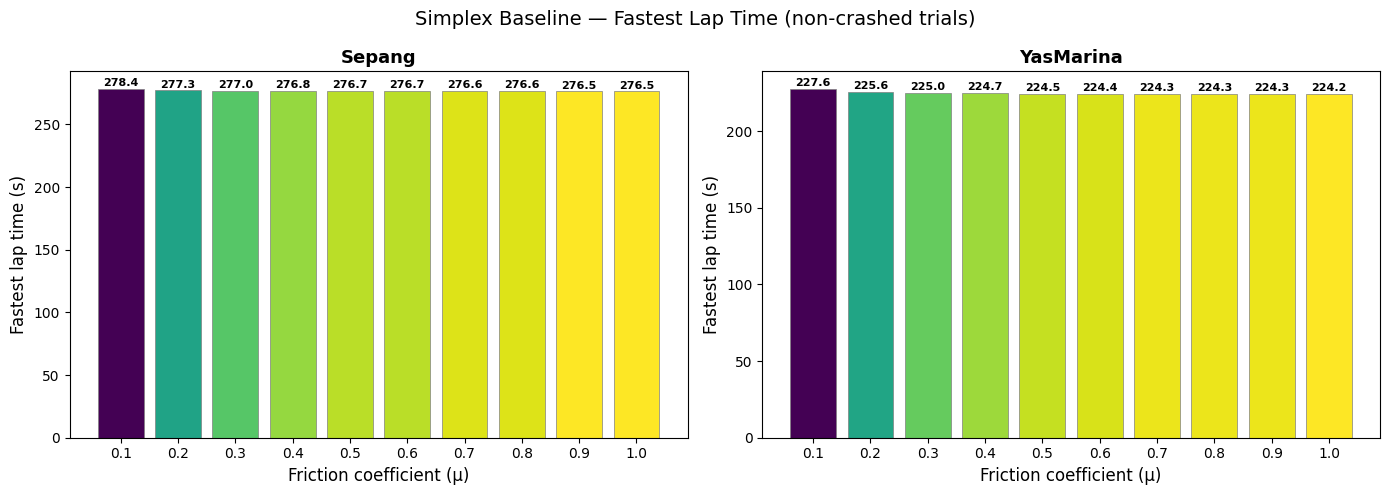

In [4]:
# --- Fastest lap time bar chart: one subplot per track ---
df_ok = df[df["collision"] == 0]

tracks = sorted(df["track"].unique())
mus = sorted(df["mu"].unique())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, track in zip(axes, tracks):
    sub = df_ok[df_ok["track"] == track].groupby("mu")["fastest_lap"].mean()
    sub = sub.reindex(mus)

    vals = sub.values.copy()
    valid = ~np.isnan(vals)
    x_labels = [f"{m:.1f}" for m in mus]

    if valid.any():
        vmin, vmax = np.nanmin(vals), np.nanmax(vals)
        norm_vals = np.where(valid, (vals - vmin) / (vmax - vmin + 1e-8), 0)
        colors = [plt.cm.viridis_r(n) if v else (0.9, 0.9, 0.9, 1.0) for n, v in zip(norm_vals, valid)]
    else:
        colors = [(0.9, 0.9, 0.9, 1.0)] * len(mus)

    bar_vals = np.where(valid, vals, 0)
    bars = ax.bar(x_labels, bar_vals, color=colors, edgecolor="gray", linewidth=0.5)

    for bar, val, v in zip(bars, vals, valid):
        if v:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                    f"{val:.1f}", ha="center", va="bottom", fontsize=8, fontweight="bold")
        else:
            ax.text(bar.get_x() + bar.get_width()/2, ax.get_ylim()[1] * 0.05,
                    "X", ha="center", va="bottom", fontsize=10, fontweight="bold", color="red")

    ax.set_xlabel("Friction coefficient (μ)", fontsize=12)
    ax.set_ylabel("Fastest lap time (s)", fontsize=12)
    ax.set_title(f"{track}", fontsize=13, fontweight="bold")

fig.suptitle("Simplex Baseline — Fastest Lap Time (non-crashed trials)", fontsize=14)
plt.tight_layout()
# plt.savefig("fastest_lap_simplex_baseline.png", dpi=150, bbox_inches="tight")
# plt.savefig("fastest_lap_simplex_baseline.pdf", bbox_inches="tight")
plt.show()


In [5]:
# --- Collision details ---
crashed = df[df["collision"] == 1]

if len(crashed) == 0:
    print("No collisions in any configuration!")
else:
    for track in sorted(crashed["track"].unique()):
        sub = crashed[crashed["track"] == track].sort_values(["mu", "seed"])
        grouped = sub.groupby("mu").agg(
            crashes=("collision", "sum"),
            seeds=("seed", lambda s: sorted(s.tolist())),
        ).reset_index()

        print(f"\n{'='*60}")
        print(f"  {track} — mu values with collisions")
        print(f"{'='*60}")
        print(f"  {'mu':>6s}  {'crashes':>7s}   seeds")
        print(f"  {'-'*40}")
        for _, row in grouped.iterrows():
            seeds_str = ", ".join(str(s) for s in row["seeds"])
            print(f"  {row['mu']:6.2f}  {row['crashes']:>7d}     [{seeds_str}]")


No collisions in any configuration!


In [6]:
# --- LaTeX table rows and crash % printout for filling in paper table ---
mus = sorted(df["mu"].unique(), reverse=True)
tracks = sorted(df["track"].unique())
df_ok = df[df["collision"] == 0]

print("Simplex Crash Percentage per mu")
print("=" * 80)

for track in tracks:
    crash = df[df["track"] == track].groupby("mu")["collision"].mean() * 100
    avg = crash.mean()
    print(f"{track:12s}  " + "  ".join([f"μ={m:.1f}: {crash.get(m,0):3.0f}%" for m in mus]) + f"  AVG: {avg:.0f}%")

print()
print("Combined (both maps):")
crash_combined = df.groupby("mu")["collision"].mean() * 100
avg_combined = crash_combined.mean()
print("  " + "  ".join([f"μ={m:.1f}: {crash_combined.get(m,0):3.0f}%" for m in mus]) + f"  AVG: {avg_combined:.0f}%")

print()
print("--- For LaTeX table (copy-paste ready, combined) ---")
row_vals = " & ".join([f"{crash_combined.get(m, 0):.0f}\\%" for m in mus])
print(f"Simplex & {row_vals} & {avg_combined:.0f}\\% \\\\")

print()
print("--- Per track rows ---")
for track in tracks:
    crash = df[df["track"] == track].groupby("mu")["collision"].mean() * 100
    avg = crash.mean()
    row_vals = " & ".join([f"{crash.get(m, 0):.0f}\\%" for m in mus])
    print(f"Simplex ({track}) & {row_vals} & {avg:.0f}\\% \\\\")

print()
print("=" * 80)
print("Simplex Fastest Lap per mu")
print("=" * 80)
fastest = df_ok.groupby(["track", "mu"])["fastest_lap"].mean()

for track in tracks:
    vals_str = "  ".join([f"μ={m:.1f}: {fastest.get((track, m), np.nan):5.1f}s" if not np.isnan(fastest.get((track, m), np.nan)) else f"μ={m:.1f}:    --" for m in mus])
    print(f"{track:12s}  {vals_str}")

# LaTeX booktabs tables
print()
print(r"% Requires: \usepackage{booktabs}")
col_spec = "c" + "c" * len(mus)
header = r"Track & " + " & ".join([f"{m:.1f}" for m in mus]) + r" \\"

print(r"\begin{table}[ht]")
print(r"\centering")
print(r"\caption{Simplex baseline crash percentage (\%) by friction coefficient.}")
print(r"\label{tab:simplex_crash_pct}")
print(f"\\begin{{tabular}}{{{col_spec}}}")
print(r"\toprule")
print(header)
print(r"\midrule")
for track in tracks:
    crash = df[df["track"] == track].groupby("mu")["collision"].mean() * 100
    vals = " & ".join([f"{crash.get(m, 0):.0f}" if crash.get(m, 0) > 0 else "0" for m in mus])
    print(f"{track} & {vals}" + r" \\")
print(r"\bottomrule")
print(r"\end{tabular}")
print(r"\end{table}")

print()
print(r"\begin{table}[ht]")
print(r"\centering")
print(r"\caption{Simplex baseline fastest lap time (s) by friction coefficient.}")
print(r"\label{tab:simplex_fastest_lap}")
print(f"\\begin{{tabular}}{{{col_spec}}}")
print(r"\toprule")
print(header)
print(r"\midrule")
for track in tracks:
    vals = " & ".join([f"{fastest.get((track, m), np.nan):.1f}" if not np.isnan(fastest.get((track, m), np.nan)) else "--" for m in mus])
    print(f"{track} & {vals}" + r" \\")
print(r"\bottomrule")
print(r"\end{tabular}")
print(r"\end{table}")


Simplex Crash Percentage per mu
Sepang        μ=1.0:   0%  μ=0.9:   0%  μ=0.8:   0%  μ=0.7:   0%  μ=0.6:   0%  μ=0.5:   0%  μ=0.4:   0%  μ=0.3:   0%  μ=0.2:   0%  μ=0.1:   0%  AVG: 0%
YasMarina     μ=1.0:   0%  μ=0.9:   0%  μ=0.8:   0%  μ=0.7:   0%  μ=0.6:   0%  μ=0.5:   0%  μ=0.4:   0%  μ=0.3:   0%  μ=0.2:   0%  μ=0.1:   0%  AVG: 0%

Combined (both maps):
  μ=1.0:   0%  μ=0.9:   0%  μ=0.8:   0%  μ=0.7:   0%  μ=0.6:   0%  μ=0.5:   0%  μ=0.4:   0%  μ=0.3:   0%  μ=0.2:   0%  μ=0.1:   0%  AVG: 0%

--- For LaTeX table (copy-paste ready, combined) ---
Simplex & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% \\

--- Per track rows ---
Simplex (Sepang) & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% \\
Simplex (YasMarina) & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% \\

Simplex Fastest Lap per mu
Sepang        μ=1.0: 276.5s  μ=0.9: 276.5s  μ=0.8: 276.6s  μ=0.7: 276.6s  μ=0.6: 276.7s  μ=0.5: 276.7s  μ=0.4: 276.8s  μ=0.3: 277.0s  μ=0.2: 27